In [55]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from tensorflow.keras.layers import Dense
from tensorflow.keras.models import Sequential


import matplotlib.pyplot as plt
import numpy as np


prepare the data

In [56]:
X,Y=load_iris(return_X_y=True)
X,Y=X[:100],Y[:100]
scaler=StandardScaler()
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.2,random_state=42)
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

Stochastic Gradient Descent (SGD)

In [57]:
model=Sequential([Dense(1,activation='sigmoid')])
model.compile(optimizer='SGD',loss='binary_crossentropy',metrics=['accuracy'])
history=model.fit(X_train,Y_train,epochs=50,batch_size=1,verbose=0)
pre=model.predict(X_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


In [58]:
loss, accuracy = model.evaluate(X_test, Y_test, verbose=0)
print(f"Test Loss: {loss:.4f} | Test Accuracy: {accuracy * 100:.2f}%")

Test Loss: 0.0088 | Test Accuracy: 100.00%


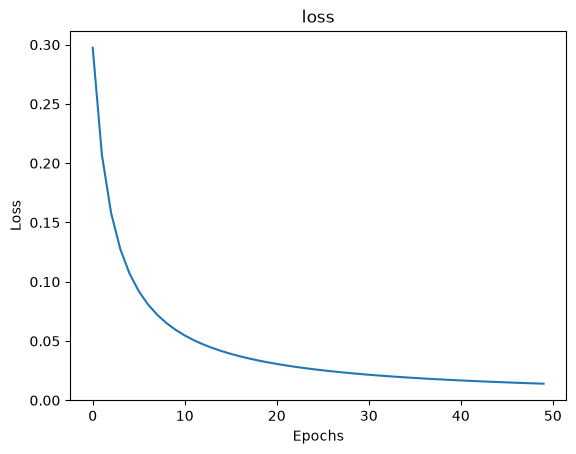

In [59]:
loss=history.history['loss']

plt.plot(loss)
plt.title("loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.show()

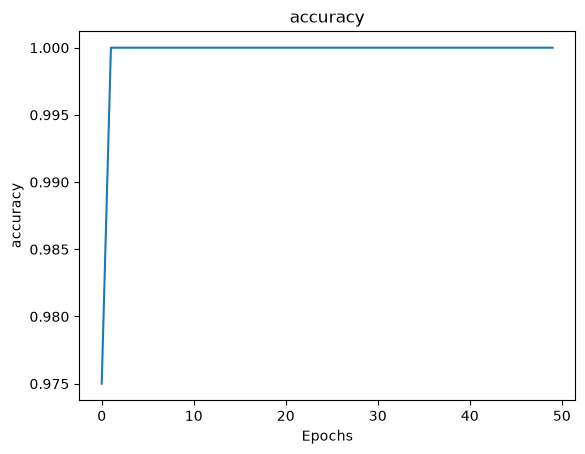

In [60]:
acc=history.history['accuracy']

plt.plot(acc)
plt.title("accuracy")
plt.xlabel("Epochs")
plt.ylabel("accuracy")
plt.show()

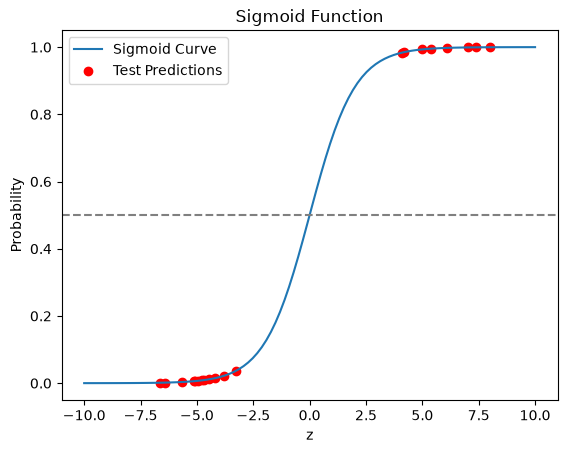

In [61]:
w,b=model.layers[0].get_weights()
z=np.dot(X_test,w)+b

z_line=np.linspace(-10,10,100)
sigmoid=1/(1+np.exp(-z_line))

plt.plot(z_line,sigmoid,label="Sigmoid Curve")
plt.scatter(z,pre,color='red',label="Test Predictions")
plt.axhline(0.5, color='gray', linestyle='--')  # خط الحد الفاصل (0.5)
plt.title("Sigmoid Function")
plt.xlabel("z")
plt.ylabel("Probability")
plt.legend()
plt.show()